**[🏠 Course Home](00_START_HERE.ipynb)** | **📖 [Conceptual](../conceptual/07_understanding_the_hessian_matrix.ipynb)** | **🐍 [Python](../python/07_understanding_the_hessian_matrix.ipynb)** | **⬅️ [Prev: Ch 06: Quadratic (Laplace) Approximation](06_quadratic_laplace_approximation.ipynb)** | **➡️ [Next: Ch 08: Discrete Markov Chains & Balance](08_markov_chains_and_detailed_balance.ipynb)**

*🧭 Part II: Numerical & Sampling Engines — Chapter 07 of 22*

---

# Chapter 7: Understanding the Hessian Matrix & Jacobian
### *From Everyday Analogies to Newton's Optimization and Bayesian Uncertainty*

---

> 📖 **Conceptual Companion**: For the physical story of bowls, domes,
> Pringles, and the bouncing ball, read **[Chapter 7: Geometric & Physical Intuitions of the Hessian Matrix](../conceptual/07_understanding_the_hessian_matrix.ipynb)**.

---

## 1. What is the Hessian Matrix? (Forget the Jargon!)
In high school calculus, you learned:
- **1st Derivative ($f'$)**: The slope.
- **2nd Derivative ($f''$)**: How the slope bends.
  - $f'' > 0 \implies$ Bends **UP** like a smile 😊 $\smile$ (You are at a
    **bottom / minimum**).
  - $f'' < 0 \implies$ Bends **DOWN** like a frown ☹️ $\frown$ (You are at a
    **top / maximum**).

### What happens when you have more than 1 variable (e.g., $x$ and $y$)?
On a 2D surface, you can walk in **infinite directions** (North, South, East,
West, North-East...). You cannot describe the curvature with just one number
anymore. You need a **grid of numbers** that tracks how the ground bends in
every possible direction: **that grid is the Hessian Matrix ($\mathbf{H}$)**.

### The Formal Mathematical Definition
For a twice-differentiable scalar function of $n$ variables
$f(x_1, x_2, \dots, x_n)$, the **Hessian matrix** $\mathbf{H}$ (or
$\nabla^2 f$) is the square $n \times n$ matrix of second-order partial
derivatives:

$$\mathbf{H}(f) = \begin{bmatrix}
\frac{\partial^2 f}{\partial x_1^2} & \frac{\partial^2 f}{\partial x_1 \partial x_2} & \cdots & \frac{\partial^2 f}{\partial x_1 \partial x_n} \\
\frac{\partial^2 f}{\partial x_2 \partial x_1} & \frac{\partial^2 f}{\partial x_2^2} & \cdots & \frac{\partial^2 f}{\partial x_2 \partial x_n} \\
\vdots & \vdots & \ddots & \vdots \\
\frac{\partial^2 f}{\partial x_n \partial x_1} & \frac{\partial^2 f}{\partial x_n \partial x_2} & \cdots & \frac{\partial^2 f}{\partial x_n^2}
\end{bmatrix}, \quad H_{ij} = \frac{\partial^2 f}{\partial x_i \partial x_j}$$

For a 2D surface $f(x, y)$ (e.g., elevation over an $(x, y)$ plane):
$$\mathbf{H}(f) = \begin{bmatrix}
f_{xx} & f_{xy} \\
f_{yx} & f_{yy}
\end{bmatrix} = \begin{bmatrix}
\frac{\partial^2 f}{\partial x^2} & \frac{\partial^2 f}{\partial x \partial y} \\
\frac{\partial^2 f}{\partial y \partial x} & \frac{\partial^2 f}{\partial y^2}
\end{bmatrix}$$

- **Diagonal elements ($f_{xx}, f_{yy}$)**: The pure curvature along the
  $x$-axis and $y$-axis.
- **Off-diagonal elements ($f_{xy}, f_{yx}$)**: The "twist" or cross-curvature
  (how the slope along $x$ changes as you move along $y$).
- **Symmetry (Schwarz's / Clairaut's Theorem)**: For smooth functions, the
  order of differentiation does not matter
  ($\frac{\partial^2 f}{\partial x \partial y} =
  \frac{\partial^2 f}{\partial y \partial x}$). Thus, **the Hessian is
  always a symmetric matrix** ($\mathbf{H} = \mathbf{H}^T$), which guarantees
  that all its eigenvalues are real numbers!

---

## 2. Demystifying the Math Terms: What does "Definite" Mean?

Mathematicians love intimidating words, but the concepts are intuitive:

| Term | What it actually means | The Shape | What critical point is it? |
| :--- | :--- | :--- | :--- |
| **Positive Definite** | **"Curves UP in EVERY direction"** (All smiles 😊) | 🥣 **A Cereal Bowl** | **Local Minimum** (a marble settles at the bottom) |
| **Negative Definite** | **"Curves DOWN in EVERY direction"** (All frowns ☹️) | 🪂 **A Dome / Umbrella** | **Local Maximum** (a marble rolls away in all directions) |
| **Indefinite** | **"Curves UP in some directions, DOWN in others"** (Mixed smile & frown) | 🥔 **A Pringle / Horse Saddle** | **Saddle Point** (it is a minimum along one axis, maximum along another) |
| **Semi-definite** | **"Curves up/down in some directions, completely FLAT in others"** | 🛹 **A Skate Halfpipe / Trench** | **A Valley / Ridge of multiple minima** |

That is literally all "positive definite" means: **it smiles in every direction**.


---
## 3. The 3 Intuitive Analogies

### 🏔️ Analogy 1: Fog on a Mountain
Imagine you are blindfolded on a landscape. You test your footing:
1. You feel the slope with your cane: **it is completely flat right here**
   ($\nabla f = 0$).
2. Now you take a tiny step North, South, East, and West:
   - If every single step goes **uphill**, you are sitting in a crater or bowl
     (**Positive Definite**).
   - If every single step goes **downhill**, you are standing on a peak
     (**Negative Definite**).
   - If North/South goes uphill, but East/West drops downhill, you are sitting
     on a mountain pass (**Indefinite**).

### 🥔 Analogy 2: The Bowl, the Dome, and the Pringle
- **Bowl**: Drop a marble anywhere, it rolls to the center. (Pure positive
  curvature).
- **Dome**: Place a marble on top, any slight push sends it falling away.
  (Pure negative curvature).
- **Pringle**: A marble placed in the center will stay trapped along the
  U-curve, but roll off the sides along the inverted-U curve. (Mixed curvature).

### 🏎️ Analogy 3: The Car and the Steering Wheel
- **Speed**: How fast your position is changing (1st derivative).
- **G-Force / Acceleration**: How the road is twisting into a banked curve
  (2nd derivative / Hessian). The steeper the bank, the higher the curvature.


In [1]:
# Verify Base R environment and required statistical packages
cat("Loading statistical libraries for Base R Hessian exploration...\n")
suppressPackageStartupMessages({
  library(MASS) # For multivariate normal simulation
})
cat("Base R environment initialized successfully!\n")


Loading statistical libraries for Base R Hessian exploration...


Base R environment initialized successfully!


---
## 4. Visualizing Canonical Curvatures & Eigenvalues in Base R

The behavior of a critical point ($\nabla f = 0$) is determined by the
**eigenvalues** of the Hessian:
- **$\lambda_1 > 0, \lambda_2 > 0$**: Positive Definite
  $\implies$ **Local Minimum**
- **$\lambda_1 < 0, \lambda_2 < 0$**: Negative Definite
  $\implies$ **Local Maximum**
- **$\lambda_1 \cdot \lambda_2 < 0$**: Indefinite
  $\implies$ **Saddle Point**

Let us generate 3D surfaces using Base R's `persp()` for all three canonical
cases side-by-side.


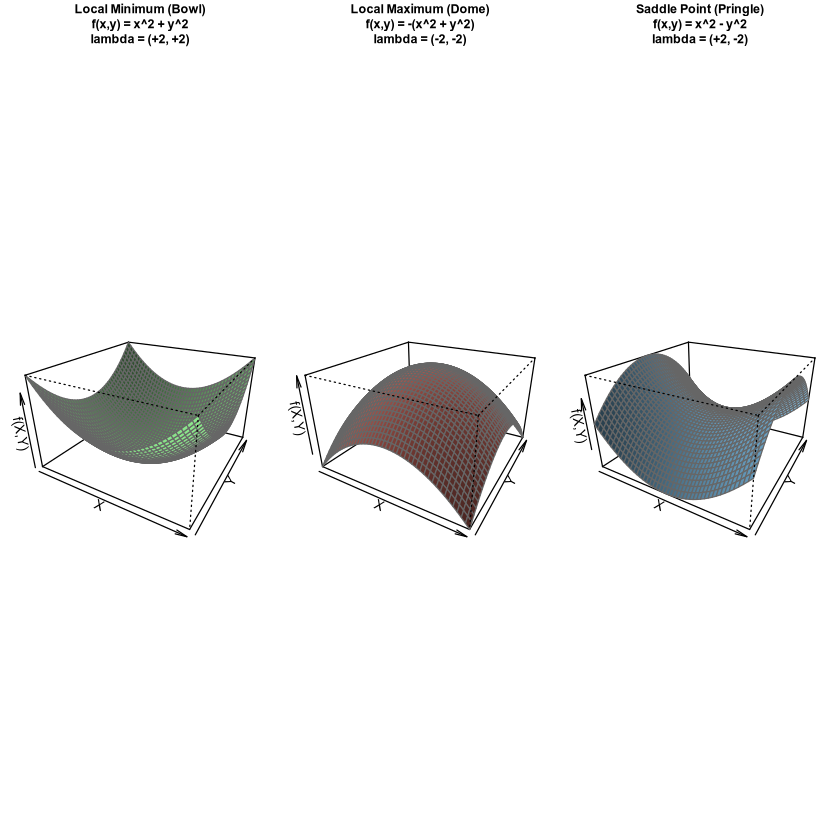

In [2]:
# Generate grid for 3D surfaces
x <- seq(-3, 3, length.out = 45)
y <- seq(-3, 3, length.out = 45)

# Three canonical surfaces
z_bowl   <- outer(x, y, function(x, y) x^2 + y^2)
z_dome   <- outer(x, y, function(x, y) -(x^2 + y^2))
z_saddle <- outer(x, y, function(x, y) x^2 - y^2)

# Set 3-panel plotting layout
par(mfrow = c(1, 3), mar = c(1, 1, 3, 1))

# Panel 1: Local Minimum (Bowl)
persp(x, y, z_bowl, theta = 30, phi = 25, expand = 0.6,
      col = "palegreen2", shade = 0.45, border = "gray40",
      main = "Local Minimum (Bowl)\nf(x,y) = x^2 + y^2\nlambda = (+2, +2)",
      xlab = "X", ylab = "Y", zlab = "f(X,Y)", cex.main = 0.95)

# Panel 2: Local Maximum (Dome)
persp(x, y, z_dome, theta = 30, phi = 25, expand = 0.6,
      col = "salmon", shade = 0.45, border = "gray40",
      main = "Local Maximum (Dome)\nf(x,y) = -(x^2 + y^2)\nlambda = (-2, -2)",
      xlab = "X", ylab = "Y", zlab = "f(X,Y)", cex.main = 0.95)

# Panel 3: Saddle Point (Pringle)
persp(x, y, z_saddle, theta = 30, phi = 25, expand = 0.6,
      col = "lightskyblue", shade = 0.45, border = "gray40",
      main = "Saddle Point (Pringle)\nf(x,y) = x^2 - y^2\nlambda = (+2, -2)",
      xlab = "X", ylab = "Y", zlab = "f(X,Y)", cex.main = 0.95)

par(mfrow = c(1, 1))


---
## 5. What About the Jacobian? (And How It Connects to the Hessian)

### The Missing Piece: Multiple Outputs!
Notice the pattern of calculus:
- **1 input $\to$ 1 output** ($y = f(x)$): The slope is a single number
  $f'(x)$.
- **Multiple inputs $\to$ 1 output** ($z = f(x, y)$): The slope is a vector:
  **Gradient ($\nabla f$)**.
- **Multiple inputs $\to$ MULTIPLE outputs**
  ($\mathbf{f}(x, y) = [u(x, y), v(x, y)]^T$): The slope is a matrix:
  **Jacobian ($\mathbf{J}$)**.

The **Jacobian** answers: *"If I nudge each input variable by a tiny amount,
how does **every single output variable** respond?"*

```
                 ┌                                           ┐
                 │  ∂f₁/∂x₁     ∂f₁/∂x₂   ...   ∂f₁/∂xₙ     │  ← Output 1 sensitivity
                 │  ∂f₂/∂x₁     ∂f₂/∂x₂   ...   ∂f₂/∂xₙ     │  ← Output 2 sensitivity
   J(f)(x)    =  │    ⋮            ⋮       ⋱       ⋮        │
                 │  ∂fₘ/∂x₁     ∂fₘ/∂x₂   ...   ∂fₘ/∂xₙ     │  ← Output m sensitivity
                 └                                           ┘
```
Each **row** of the Jacobian is simply the **gradient of one output**!

---

### Two Intuitive Analogies for the Jacobian

#### 🤖 1. The Robotic Arm (Inputs: Joint Angles $\to$ Coordinates)
Think of a factory robotic arm with two pivot joints ($\theta_1$ and
$\theta_2$):
- **Inputs**: The 2 motor angles $[\theta_1, \theta_2]^T$.
- **Outputs**: The tip's $(x, y)$ position in Cartesian 2D space.
- **The Jacobian**: Tells the control system how many millimeters the tip moves
  in $x$ and $y$ for every degree of motor rotation.

#### 🎈 2. The Stretchy Rubber Sheet (Grid Distortion)
Draw a square grid on a sheet of rubber and stretch it unevenly:
- A square turns into a tilted, stretched parallelogram.
- **The Jacobian matrix** describes the local stretch and shear.
- **The Determinant $|\det(\mathbf{J})|$** tells you the **area magnification
  factor** (how much a tiny square balloon expands or shrinks).

---

### The Fundamental Link Between the Jacobian and the Hessian

> **The Hessian is just the Jacobian of the Gradient!**
> $$\mathbf{H}(f) = \mathbf{J}(\nabla f)$$

When $f(x_1, \dots, x_n)$ maps $n$ inputs to 1 output, its **Gradient**
$\nabla f$ maps $n$ inputs to $n$ outputs (the slopes).
The **Jacobian of that Gradient vector** is an $n \times n$ matrix of slopes of
slopes: **the Hessian Matrix**!


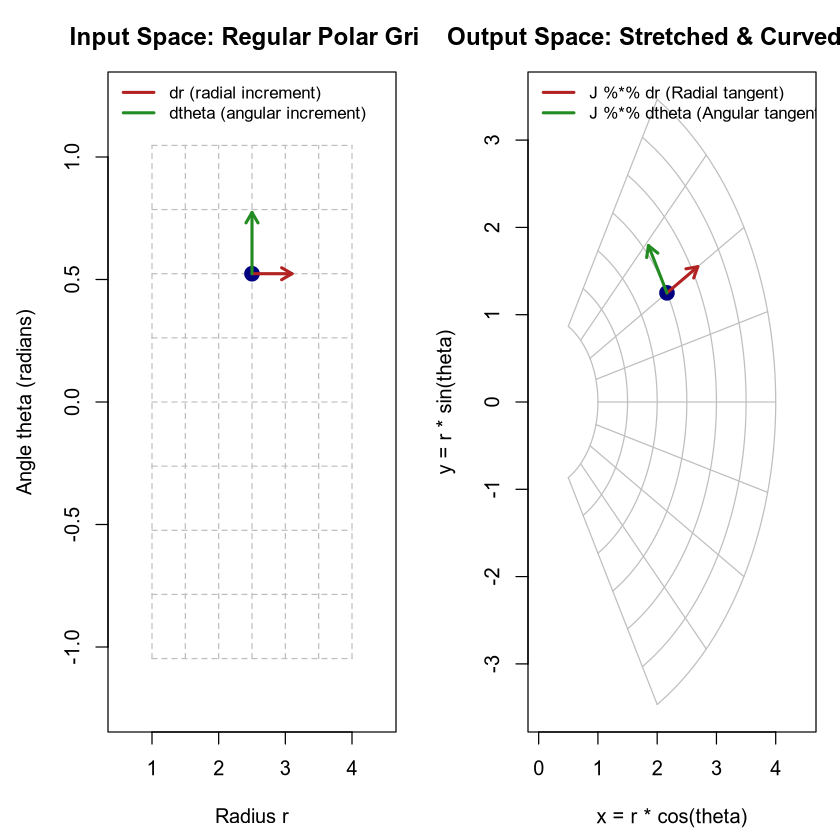

In [3]:
# Visualizing a 2D coordinate transformation and its Jacobian in Base R
# Mapping polar coordinates (r, theta) -> Cartesian (x, y)
# x = r * cos(theta), y = r * sin(theta)

par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))

r_vals  <- seq(1.0, 4.0, by = 0.5)
th_vals <- seq(-pi/3, pi/3, by = pi/12)

# Panel 1: Input Space (r, theta)
plot(NA, xlim = c(0.5, 4.5), ylim = c(-pi/3 - 0.2, pi/3 + 0.2),
     xlab = "Radius r", ylab = "Angle theta (radians)",
     main = "Input Space: Regular Polar Grid", font.main = 2)
for (r in r_vals) lines(c(r, r), range(th_vals), col = "gray75", lty = 2)
for (th in th_vals) lines(range(r_vals), c(th, th), col = "gray75", lty = 2)

# Highlight evaluation point
r0 <- 2.5; th0 <- pi/6
points(r0, th0, pch = 19, col = "navy", cex = 1.6)
arrows(r0, th0, r0 + 0.6, th0, col = "firebrick", lwd = 2.5, length = 0.1)
arrows(r0, th0, r0, th0 + 0.25, col = "forestgreen", lwd = 2.5, length = 0.1)
legend("topleft",
       legend = c("dr (radial increment)", "dtheta (angular increment)"),
       col = c("firebrick", "forestgreen"), lwd = 2.5, bty = "n", cex = 0.85)

# Panel 2: Output Space (Cartesian x, y)
plot(NA, xlim = c(0, 4.5), ylim = c(-3.5, 3.5),
     xlab = "x = r * cos(theta)", ylab = "y = r * sin(theta)",
     main = "Output Space: Stretched & Curved by J", font.main = 2)

th_dense <- seq(-pi/3, pi/3, length.out = 100)
for (r in r_vals) lines(r * cos(th_dense), r * sin(th_dense), col = "gray75")

r_dense <- seq(1.0, 4.0, length.out = 100)
for (th in th_vals) lines(r_dense * cos(th), r_dense * sin(th), col = "gray75")

x0 <- r0 * cos(th0); y0 <- r0 * sin(th0)
points(x0, y0, pch = 19, col = "navy", cex = 1.6)

# Jacobian vector tangents:
# Column 1 = d(x,y)/dr = [cos(th), sin(th)]
# Column 2 = d(x,y)/dth = [-r*sin(th), r*cos(th)]
j_col1 <- c(cos(th0), sin(th0)) * 0.6
j_col2 <- c(-r0 * sin(th0), r0 * cos(th0)) * 0.25

arrows(x0, y0, x0 + j_col1[1], y0 + j_col1[2],
       col = "firebrick", lwd = 2.5, length = 0.1)
arrows(x0, y0, x0 + j_col2[1], y0 + j_col2[2],
       col = "forestgreen", lwd = 2.5, length = 0.1)
legend("topleft",
       legend = c("J %*% dr (Radial tangent)",
                  "J %*% dtheta (Angular tangent)"),
       col = c("firebrick", "forestgreen"), lwd = 2.5, bty = "n", cex = 0.85)

par(mfrow = c(1, 1))


---
## 6. Symbolic Calculus: Proving $\mathbf{H}(f) = \mathbf{J}(
abla f)$

Let us use Base R's symbolic differentiation engine `D()` to analytically
calculate the Gradient, Jacobian, and Hessian for:
$$f(x, y) = x^3 - 3xy^2 + y^3$$
And verify that the **Jacobian of the Gradient vector** is identical to the
**Hessian matrix**!


In [4]:
# Define mathematical expression in Base R
f_expr <- expression(x^3 - 3 * x * y^2 + y^3)
cat("Target function f(x, y) = x^3 - 3*x*y^2 + y^3\n\n")

# 1. Gradient: nabla f = [df/dx, df/dy]
df_dx <- D(f_expr, "x")
df_dy <- D(f_expr, "y")
cat("1. Gradient Vector Components:\n")
cat("   df/dx =", deparse(df_dx), "\n")
cat("   df/dy =", deparse(df_dy), "\n\n")

# 2. Jacobian of the Gradient Vector: J(nabla f)
# Row 1: d/dx(df/dx), d/dy(df/dx)
j11 <- D(df_dx, "x")
j12 <- D(df_dx, "y")
# Row 2: d/dx(df/dy), d/dy(df/dy)
j21 <- D(df_dy, "x")
j22 <- D(df_dy, "y")

cat("2. Jacobian Matrix of the Gradient J(nabla f):\n")
cat("   J_11 =", deparse(j11), "\n")
cat("   J_12 =", deparse(j12), "\n")
cat("   J_21 =", deparse(j21), "\n")
cat("   J_22 =", deparse(j22), "\n\n")

# 3. Direct Hessian Second Partials: H(f)
h11 <- D(D(f_expr, "x"), "x")
h12 <- D(D(f_expr, "x"), "y")
h21 <- D(D(f_expr, "y"), "x")
h22 <- D(D(f_expr, "y"), "y")

cat("3. Hessian Matrix Components H(f):\n")
cat("   H_11 =", deparse(h11), "\n")
cat("   H_12 =", deparse(h12), "\n")
cat("   H_21 =", deparse(h21), "\n")
cat("   H_22 =", deparse(h22), "\n\n")

# 4. Programmatic Verification across test coordinates
test_pts <- list(c(x = 1, y = 2), c(x = -2, y = 3), c(x = 0.5, y = -1.5))
for (pt in test_pts) {
  env <- as.list(pt)
  j_val <- matrix(c(eval(j11, env), eval(j21, env),
                    eval(j12, env), eval(j22, env)), nrow = 2)
  h_val <- matrix(c(eval(h11, env), eval(h21, env),
                    eval(h12, env), eval(h22, env)), nrow = 2)
  stopifnot(all.equal(j_val, h_val))
}
cat("SUCCESS: Programmatic verification confirmed: J(nabla f) == H(f)!\n")


Target function f(x, y) = x^3 - 3*x*y^2 + y^3



1. Gradient Vector Components:


   df/dx = 3 * x^2 - 3 * y^2 


   df/dy = 3 * y^2 - 3 * x * (2 * y) 



2. Jacobian Matrix of the Gradient J(nabla f):


...

   H_11 = 3 * (2 * x) 


   H_12 = -(3 * (2 * y)) 


   H_21 = -(3 * (2 * y)) 


   H_22 = 3 * (2 * y) - 3 * x * 2 



SUCCESS: Programmatic verification confirmed: J(nabla f) == H(f)!


---
## 7. Application 1: Optimization (Gradient Descent vs. Newton's Method)

### Why Gradient Descent Struggles in Narrow Ravines
Standard Gradient Descent takes steps proportional to the negative gradient:
$$\mathbf{x}_{t+1} = \mathbf{x}_t - \alpha \nabla f(\mathbf{x}_t)$$
The gradient is orthogonal to contour lines. In a narrow, elongated valley
(anisotropic curvature where one eigenvalue is huge and the other is tiny), the
gradient points almost perpendicularly across the valley walls rather than
along the gentle path to the minimum. This causes **severe oscillations
(zig-zagging)**!

### How the Hessian Rescales the Universe: Newton's Method
Newton's method approximates $f$ around the current point using a 2nd-order
Taylor expansion:
$$f(\mathbf{x} + \Delta \mathbf{x}) \approx f(\mathbf{x}) + \nabla f(\mathbf{x})^T \Delta \mathbf{x} + \frac{1}{2} \Delta \mathbf{x}^T \mathbf{H} \Delta \mathbf{x}$$
Setting the derivative with respect to $\Delta \mathbf{x}$ to zero gives the
**Newton step**:
$$\Delta \mathbf{x} = - \mathbf{H}^{-1} \nabla f(\mathbf{x})$$

$\mathbf{H}^{-1}$ acts as a **preconditioner**:
1. It **de-correlates** the coordinates by rotating into the principal
   curvature directions (eigenvectors).
2. It **scales** each step inversely by the curvature ($1/\lambda_i$). Steep
   directions get small steps; flat directions get large steps.
3. For any quadratic function, **Newton's method jumps to the exact minimum in
   exactly ONE step!**


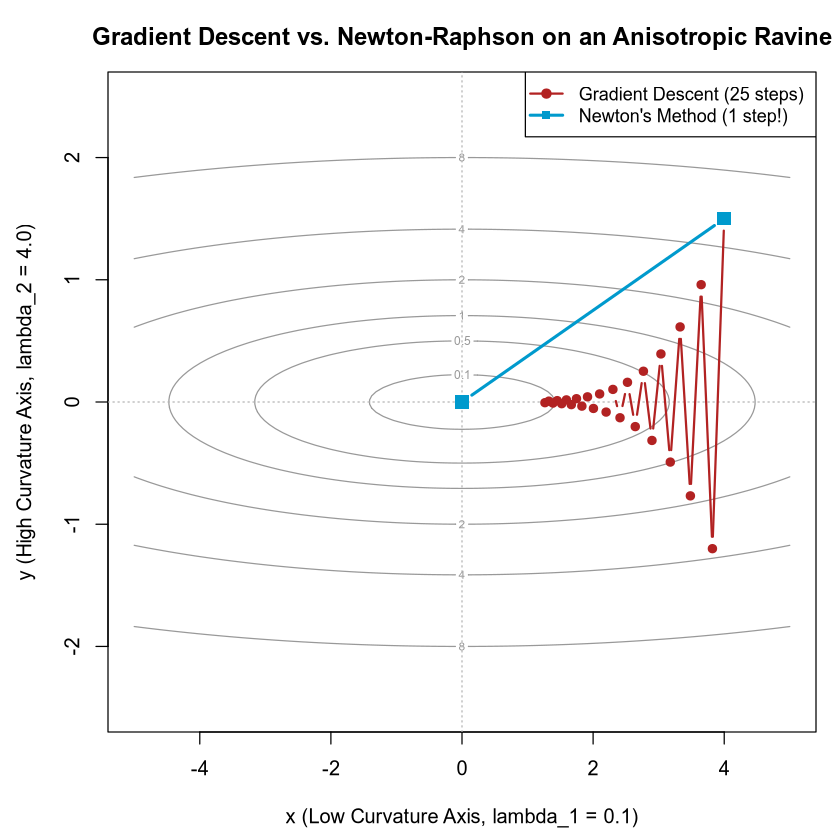

In [5]:
# Define an ill-conditioned quadratic bowl: f(x, y) = 0.05 * x^2 + 2.0 * y^2
# Curvature along X is 0.1 (very flat), curvature along Y is 4.0 (very steep)
f_quad <- function(x, y) 0.05 * x^2 + 2.0 * y^2
grad_quad <- function(pt) c(0.1 * pt[1], 4.0 * pt[2])
H_quad <- matrix(c(0.1, 0.0, 0.0, 4.0), nrow = 2)

# 1. Gradient Descent Simulation
start_pt <- c(4.0, 1.5)
lr <- 0.45  # If lr > 0.5, GD diverges along Y!
gd_path <- matrix(NA, nrow = 26, ncol = 2)
gd_path[1, ] <- start_pt
curr <- start_pt

for (step in 1:25) {
  curr <- curr - lr * grad_quad(curr)
  gd_path[step + 1, ] <- curr
}

# 2. Newton's Method Simulation
newton_step <- start_pt - solve(H_quad) %*% grad_quad(start_pt)
newton_path <- rbind(start_pt, as.vector(newton_step))

# Plot Comparison in Base R
x_vals <- seq(-5, 5, length.out = 150)
y_vals <- seq(-2.5, 2.5, length.out = 150)
z_vals <- outer(x_vals, y_vals, f_quad)

par(mar = c(4.5, 4.5, 3, 1))
contour(x_vals, y_vals, z_vals, levels = c(0.1, 0.5, 1, 2, 4, 8, 16, 32),
        col = "gray60", xlab = "x (Low Curvature Axis, lambda_1 = 0.1)",
        ylab = "y (High Curvature Axis, lambda_2 = 4.0)",
        main = "Gradient Descent vs. Newton-Raphson on an Anisotropic Ravine",
        font.main = 2)
abline(h = 0, v = 0, lty = 3, col = "gray70")

# Draw Gradient Descent trajectory
lines(gd_path[, 1], gd_path[, 2], type = "b", pch = 19, col = "firebrick",
      lwd = 1.8, cex = 0.8)

# Draw Newton-Raphson 1-step trajectory
lines(newton_path[, 1], newton_path[, 2], type = "b", pch = 15,
      col = "deepskyblue3", lwd = 2.5, cex = 1.5)

legend("topright",
       legend = c(sprintf("Gradient Descent (%d steps)", nrow(gd_path) - 1),
                  "Newton's Method (1 step!)"),
       col = c("firebrick", "deepskyblue3"), pch = c(19, 15),
       lty = 1, lwd = c(1.8, 2.5), bg = "white", cex = 0.9)


---
## 8. Application 2: Statistics & Uncertainty (Laplace Approximation)

In Bayesian statistics and Maximum Likelihood Estimation (MLE):
- Finding the peak of the log-posterior or log-likelihood gives the **Maximum A
  Posteriori (MAP)** or **MLE** estimate $\hat{\theta}$.
- But how confident are we in that estimate?

### The Hessian as the Precision Matrix
The curvature at the peak tells us how sharply the likelihood drops off:
- **Sharp, narrow peak** $\implies$ High curvature $\implies$ Large Hessian
  eigenvalues $\implies$ **High certainty / Low variance**.
- **Broad, flat plateau** $\implies$ Low curvature $\implies$ Small Hessian
  eigenvalues $\implies$ **High uncertainty / High variance**.

Under the **Laplace Approximation**, the posterior distribution is
approximated as a Gaussian:
$$\mathcal{N}\left(\hat{\theta}, \,\mathbf{\Sigma}\right) \quad \text{where} \quad \mathbf{\Sigma} = \mathbf{H}^{-1} = \left(-\nabla^2 \ln p(\theta \mid \mathcal{D})\right)^{-1}$$

**The Hessian of the negative log-posterior is directly the Fisher
Information / Precision matrix!**

> [!NOTE]
> **Curriculum Connection**: This inverse-curvature relationship
> $\mathbf{\Sigma} = \mathbf{H}^{-1}$ forms the core engine of **[Chapter 6:
> Rapid Prototyping — Quadratic (Laplace / QUAP)
> Approximation](06_quadratic_laplace_approximation.ipynb)**, where an
> optimizer sprints to $\hat{\theta}_{\text{MAP}}$ and numerically extracts
> the Hessian to immediately construct the parameter covariance matrix.


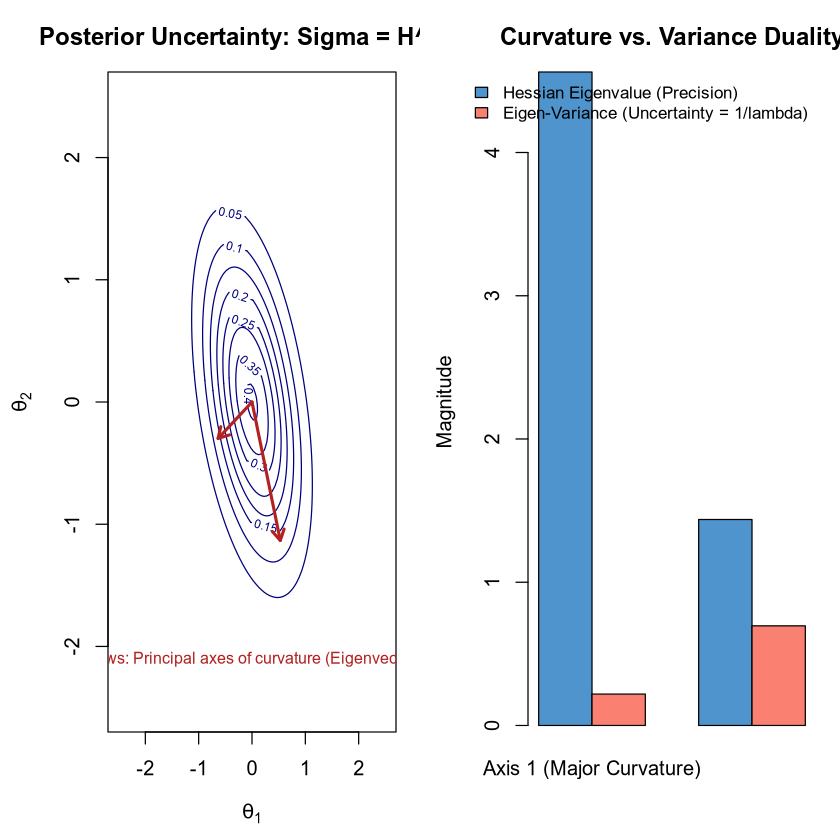

In [6]:
# Illustrating Curvature vs. Parameter Uncertainty in Base R
# Covariance matrix derived from inverse Hessian of negative log-likelihood
H_neg_log_lik <- matrix(c(
  4.0, 1.2,
  1.2, 2.0
), nrow = 2, byrow = TRUE)

# Parameter Covariance Sigma = H^(-1)
Sigma <- solve(H_neg_log_lik)
mean_vec <- c(0, 0)

# Decompose Hessian into eigenvalues and eigenvectors
eg <- eigen(H_neg_log_lik)
w <- eg$values     # Curvatures (precisions)
v <- eg$vectors    # Principal axes

par(mfrow = c(1, 2), mar = c(4.5, 4.5, 3, 1))

# Panel 1: Posterior Density Contours
theta1 <- seq(-2.5, 2.5, length.out = 100)
theta2 <- seq(-2.5, 2.5, length.out = 100)
grid_coords <- expand.grid(t1 = theta1, t2 = theta2)
det_Sigma <- det(Sigma)
norm_constant <- 1 / (2 * pi * sqrt(det_Sigma))

density_vals <- apply(grid_coords, 1, function(pt) {
  diff <- pt - mean_vec
  norm_constant * exp(-0.5 * t(diff) %*% H_neg_log_lik %*% diff)
})
density_mat <- matrix(density_vals, nrow = 100, ncol = 100)

contour(theta1, theta2, density_mat, nlevels = 12, col = "navy",
        xlab = expression(theta[1]), ylab = expression(theta[2]),
        main = "Posterior Uncertainty: Sigma = H^(-1)", font.main = 2)

# Overlay principal curvature axes (eigenvectors of H scaled by 1/sqrt(lambda))
for (i in 1:2) {
  axis_vec <- v[, i] / sqrt(w[i]) * 1.5
  arrows(0, 0, axis_vec[1], axis_vec[2],
         col = "firebrick", lwd = 2.5, length = 0.1)
}
text(0.0, -2.1, "Red arrows: Principal axes of curvature (Eigenvectors of H)",
     col = "firebrick", cex = 0.8)

# Panel 2: Barplot of Eigenvalues (Precision) vs Variances (Uncertainty)
variances <- 1.0 / w
bar_matrix <- rbind(w, variances)
barplot(bar_matrix, beside = TRUE, col = c("steelblue3", "salmon"),
        names.arg = c("Axis 1 (Major Curvature)", "Axis 2 (Minor Curvature)"),
        main = "Curvature vs. Variance Duality", ylab = "Magnitude",
        legend.text = c("Hessian Eigenvalue (Precision)",
                        "Eigen-Variance (Uncertainty = 1/lambda)"),
        args.legend = list(x = "topright", bty = "n", cex = 0.85),
        font.main = 2)

par(mfrow = c(1, 1))


---
## 9. Summary Cheat Sheet

| Concept | What It Tells You | Dimension |
| :--- | :--- | :--- |
| **Function $f(x)$** | Where you are (Height / Elevation) | Scalar ($1 \times 1$) |
| **Gradient $\nabla f(x)$** | Which direction slopes steepest uphill (Slope of 1 output) | Vector ($n \times 1$) |
| **Jacobian $\mathbf{J}(x)$** | Slopes when you have multiple outputs (Stretch & Shear) | Matrix ($m \times n$) |
| **Hessian $\mathbf{H}(x) = \mathbf{J}(\nabla f)$** | How the slope changes in all directions (Curvature) | Matrix ($n \times n$) |
| **Determinant $\det(\mathbf{J})$** | Local volume/area magnification factor of mapping | Scalar |
| **Eigenvectors of $\mathbf{H}$** | The principal directions of curvature | $n$ vectors in $\mathbb{R}^n$ |
| **Eigenvalues of $\mathbf{H}$** | The degree of bending along each principal direction | $n$ scalars |
| **Newton's Step $-\mathbf{H}^{-1}\nabla f$** | Direct jump to local quadratic minimum | Vector ($n \times 1$) |
| **Covariance $\mathbf{\Sigma} \approx \mathbf{H}^{-1}$** | Parameter uncertainty in Bayesian estimation | Covariance Matrix ($n \times n$) |


---
## 🎯 Check Your Understanding: 3-Tier Scaffolding Exercises

Sharpen your intuition and practice the mathematical concepts introduced in
this appendix. Write your solutions in the interactive attempt cells below
before expanding the verified solutions.

---

### 🟢 Tier 1 (Warm-Up): Inverting the 1D Hessian Curvature
> **Scenario**: You optimize a 1D log-posterior and find the MAP mode at
> $\theta^* = 10.0$.
> The second derivative (Hessian) at the mode is computed as
> $H = \frac{d^2 \ln p(\theta \mid D)}{d\theta^2} = -25.0$.
> 1. What is the observed Fisher Information $\mathcal{I}$?
> 2. What is the estimated standard deviation $\sigma_{\theta}$ of the posterior
>    under the Laplace approximation?
> 3. Formulate the $95\%$ Credible Interval for $\theta$.


In [7]:
# ============================================================
# 🟢 Tier 1: Your Turn — Attempt the Problem Here
# ============================================================
theta_mode <- 10.0
hessian_val <- -25.0

# 1. Observed Fisher Information: I = -H
# fisher_info <- ...

# 2. Variance and Standard Deviation:
# post_var <- ...
# post_sd  <- ...

# 3. 95% Credible Interval:
# ci_lower <- ...
# ci_upper <- ...


<details>
<summary><b>🔍 Click here to view the solution & derivation</b></summary>

**Answer**:
1. **Observed Fisher Information**:
   $$\mathcal{I} = -H = -(-25.0) = 25.0$$
2. **Posterior Variance & Std Dev**:
   $$\sigma^2 = \mathcal{I}^{-1} = \frac{1}{25.0} = 0.04$$
   $$\sigma = \sqrt{0.04} = 0.20$$
   Under QUAP, the posterior is approximated as
   $\text{Normal}(\mu = 10.0, \sigma = 0.20)$.
3. **$95\%$ Credible Interval**:
   $$10.0 \pm 1.96(0.20) = [9.61, 10.39]$$

```r
fisher_info <- -hessian_val
post_sd <- sqrt(1 / fisher_info)
ci_95 <- theta_mode + c(-1.96, 1.96) * post_sd
cat(sprintf("Fisher Info: %.1f | SD: %.2f | 95%% CI: [%.2f, %.2f]\n",
            fisher_info, post_sd, ci_95[1], ci_95[2]))
```
</details>


---
### 🟡 Tier 2 (Guided Calculation): Bounded Parameters & QUAP Failure
> **Scenario**: An engineer uses QUAP directly on a binomial failure probability
> $\theta \in [0, 1]$ after observing $2$ failures in $50$ runs.
> The quadratic approximation yields $\hat{\theta} = 0.04$ with estimated std
> dev $\hat{\sigma} = 0.025$.
> 1. Calculate the standard Gaussian $95\%$ Credible Interval:
>    $\hat{\theta} \pm 1.96\hat{\sigma}$.
> 2. Why is this interval physically impossible in software systems?
> 3. What mathematical parameter transformation cures this pathology?


In [8]:
# ============================================================
# 🟡 Tier 2: Your Turn — Attempt the Problem Here
# ============================================================
theta_hat <- 0.04
sigma_hat <- 0.025

# 1. Compute standard Gaussian 95% interval:
# lower_raw <- ...
# upper_raw <- ...

# 2. Logit transformation: phi = log(theta / (1 - theta))
# phi_hat <- qlogis(theta_hat)


<details>
<summary><b>🔍 Click here to view the solution & remedy</b></summary>

**Answer**:
1. **Gaussian Interval**:
   $$0.04 \pm 1.96(0.025) = 0.04 \pm 0.049 = [-0.009, 0.089] = [-0.90\%, 8.90\%]$$
2. **Physical Impossibility**: The interval extends below zero into **negative
   probability territory** ($-0.90\%$ failure rate), which is nonsensical.
3. **Remedy (Logit Link)**: Transform the bounded parameter to the unconstrained
   real line using the log-odds (logit) function:
   $$\phi = \text{logit}(\theta) = \log\left(\frac{\theta}{1 - \theta}\right) \in (-\infty, +\infty)$$
   Run QUAP on $\phi$ (which is unconstrained on the real line), and then
   project back using the logistic sigmoid $\theta = \frac{1}{1 + e^{-\phi}}$
   (in Base R: `plogis()`). The resulting interval is guaranteed to lie
   strictly in $(0, 1)$!
</details>


---
### 🔴 Tier 3 (Production Challenge): Diagonalizing the Hessian Matrix
> **Scenario**: When fitting a linear regression
> $y_i \sim \text{Normal}(\alpha + \beta x_i, \sigma)$, a data scientist leaves
> the predictor $x$ uncentered (e.g., calendar year:
> $x = [2021, 2022, 2023, 2024, 2025]$).
> 1. What happens to the off-diagonal elements of the Hessian matrix
>    $\frac{\partial^2 L}{\partial \alpha \partial \beta}$?
> 2. How does this affect optimization speed and parameter correlation?
> 3. How does mean-centering $x_i' = x_i - \bar{x}$ eliminate this pathology?


In [9]:
# ============================================================
# 🔴 Tier 3: Your Turn — Attempt the Problem Here
# ============================================================
x_uncentered <- c(2021, 2022, 2023, 2024, 2025)

# Cross-derivative term is proportional to sum(x):
sum_uncentered <- sum(x_uncentered)

# Centered version:
x_centered <- x_uncentered - mean(x_uncentered)
sum_centered <- sum(x_centered)

cat(sprintf("Sum Uncentered: %.1f | Sum Centered: %.1f\n",
            sum_uncentered, sum_centered))


Sum Uncentered: 10115.0 | Sum Centered: 0.0


<details>
<summary><b>🔍 Click here to view the solution & covariance algebra</b></summary>

**Explanation & Proof**:
1. **Off-Diagonal Hessian**: The cross-partial derivative of the sum of squared
   errors with respect to $\alpha$ and $\beta$ is proportional to $\sum x_i$.
   When $x$ values are large (like year 2023), $\sum x_i = 10,115$, creating
   extreme off-diagonal covariance.
2. **Pathological Correlation**: The joint posterior becomes a razor-thin,
   highly diagonal elliptical canyon. Changing $\beta$ by a tiny amount forces
   a gigantic compensation in $\alpha$ (the intercept at year 0), causing
   gradient optimizers to stall and bounce between valley walls.
3. **Centering Solution**: When you transform to $x_i' = x_i - \bar{x}$, by
   definition $\sum x_i' = 0$.
   The cross-partial derivative vanishes completely:
   $$\frac{\partial^2 L}{\partial \alpha \partial \beta} = 0$$
   The Hessian becomes **block-diagonal**, $\alpha$ (mean at average $x$) and
   $\beta$ (slope) become orthogonal and uncorrelated, and the optimizer
   converges instantaneously in a circular, well-conditioned bowl.
</details>


---


---
## 🧭 Course Navigation

* 🏠 **[Course Home & Master Syllabus](00_START_HERE.ipynb)**
* ⬅️ **Previous**: **[Ch 06: Quadratic (Laplace) Approximation](06_quadratic_laplace_approximation.ipynb)** *(Part II: Numerical & Sampling Engines)*
* ➡️ **Next**: **[Ch 08: Discrete Markov Chains & Balance](08_markov_chains_and_detailed_balance.ipynb)** *(Part II: Numerical & Sampling Engines)*
* 🔄 **Companion Tracks for Chapter 07**: [📖 Conceptual](../conceptual/07_understanding_the_hessian_matrix.ipynb) | [🐍 Python](../python/07_understanding_the_hessian_matrix.ipynb) | [🔵 R](../r/07_understanding_the_hessian_matrix.ipynb)
